# Developer Experience vs. Bug-Inducing Rate in Agentic PRs

Data source: Mazloomzadeh et al., RQ3 dataset ([arXiv:2607.21832](https://arxiv.org/abs/2607.21832), [GitHub repository](https://github.com/mazloomzadeh/AI-Agent-Analysis)). Downloaded files and the merged cohort are cached in `data_cache/`.

In [1]:
from bisect import bisect_left
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

DATA_DIR = Path("data_cache")
DATA_DIR.mkdir(exist_ok=True)

AGENTS = ["claude", "codex", "cursor"]
PR_URL_RE = r"(?:repos|github\.com)/([^/]+/[^/]+)/pulls?/(\d+)"


def format_p_value(value):
    return "<0.001" if value < 0.001 else f"{value:.3f}"


def get_csv(url, filename):
    path = DATA_DIR / filename
    if not path.exists():
        print(f"Downloading {filename}...")
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=180) as resp:
            path.write_bytes(resp.read())
    return path


def count_prior_merged_prs(pr_history):
    merged_dates = (
        pr_history.loc[pr_history["is_merged"].eq(1)]
        .groupby(["repo_lower", "user_lower"])["pr_closed_dt"]
        .apply(lambda dates: sorted(dates.dropna().tolist()))
        .to_dict()
    )

    return pd.Series(
        [
            bisect_left(merged_dates.get((repo, user), ()), created)
            for repo, user, created in zip(
                pr_history["repo_lower"],
                pr_history["user_lower"],
                pr_history["pr_created_dt"],
            )
        ],
        index=pr_history.index,
        dtype=int,
    )

## Download dataset files

The analysis excludes `copilot` and `devin` because their bot author accounts do not identify the developer needed to calculate prior experience. The cohort includes the complete balanced RQ3 samples for Claude, Codex, and Cursor. One Claude-labeled PR has the `Copilot` bot as its author.

In [2]:
BASE_RAW = "https://raw.githubusercontent.com/mazloomzadeh/AI-Agent-Analysis/main"
BASE_LFS = "https://media.githubusercontent.com/media/mazloomzadeh/AI-Agent-Analysis/main"

bug_csv = get_csv(
    f"{BASE_RAW}/RQ3/Analysis_Part2/which_prs_are_bug_inducing_which_not_all_agents.csv",
    "bug_inducing.csv",
)

info_csvs = {
    a: get_csv(
        f"{BASE_RAW}/RQ3/Analysis_Part1/prs_general_info_with_contributors/{a}_prs_general_info_with_comments_contributors_count.csv",
        f"{a}_info.csv",
    )
    for a in AGENTS
}

all_prs_csvs = {
    a: get_csv(
        f"{BASE_LFS}/all_prs/{a}_filtered_prs_info_between_release_date_and_cutoff_date.csv",
        f"{a}_all_prs.csv",
    )
    for a in AGENTS
}

## Build the cohort and calculate prior experience

Experience is the number of PRs by the same author merged into the same repository before the selected PR's creation time. The calculation uses the full repository PR history in `all_prs`.

In [3]:
cohort_csv = DATA_DIR / "rq3_cohort_point_in_time.csv"

if not cohort_csv.exists():
    bug_df = pd.read_csv(bug_csv, usecols=["pr_url", "pr_type", "agent", "is_bug_inducing"])
    info_df = pd.concat(
        [
            pd.read_csv(
                info_csvs[a],
                usecols=["pr_url", "pr_type", "agent", "pr_username", "pr_usertype", "created_at"],
            )
            for a in AGENTS
        ],
        ignore_index=True,
    )

    rq3 = bug_df.merge(info_df, on=["pr_url", "pr_type", "agent"])
    rq3 = rq3[rq3["agent"].isin(AGENTS)].copy()

    hist_cols = [
        "pr_url",
        "repo_fullname",
        "pr_user",
        "pr_user_type",
        "pr_created_date",
        "pr_closed_date",
        "pr_merge_user",
    ]
    all_prs = pd.concat([pd.read_csv(all_prs_csvs[a], usecols=hist_cols) for a in AGENTS], ignore_index=True)

    matches = all_prs["pr_url"].str.extract(PR_URL_RE)
    all_prs["pr_key"] = matches[0].str.lower() + "#" + matches[1]
    all_prs["repo_lower"] = all_prs["repo_fullname"].astype(str).str.lower()
    all_prs["user_lower"] = all_prs["pr_user"].astype(str).str.lower()
    all_prs["pr_created_dt"] = pd.to_datetime(all_prs["pr_created_date"], utc=True)
    all_prs["pr_closed_dt"] = pd.to_datetime(all_prs["pr_closed_date"], utc=True)
    all_prs["is_merged"] = all_prs["pr_merge_user"].notna().astype(int)

    unique_prs = (
        all_prs.drop_duplicates(subset=["pr_key"])
        .sort_values(["pr_created_dt", "pr_key"])
        .reset_index(drop=True)
    )

    unique_prs["prior_merged_prs"] = count_prior_merged_prs(unique_prs)

    matches = rq3["pr_url"].str.extract(PR_URL_RE)
    rq3["pr_key"] = matches[0].str.lower() + "#" + matches[1]
    rq3 = rq3.merge(
        unique_prs[["pr_key", "prior_merged_prs"]],
        on="pr_key",
        how="left",
    )
    rq3["is_bug"] = (rq3["is_bug_inducing"] == "BI").astype(int)
    rq3.to_csv(cohort_csv, index=False)

rq3 = pd.read_csv(cohort_csv)
rq3["is_agentic"] = (rq3["pr_type"] == "AM").astype(int)

## Fit the interaction model

The logistic model is `is_bug ~ is_agentic * experience`. Experience is the raw count of prior merged PRs, so its coefficient is the change in log-odds per additional PR. The model assumes a linear effect on the log-odds scale and uses the non-robust standard errors provided by `statsmodels` by default.

$$
\operatorname{logit}\!\left[P(\mathrm{bug}=1)\right]
= \beta_0 + \beta_1 A + \beta_2 E + \beta_3(A \times E)
$$

$A$ is 0 for human PRs and 1 for agentic PRs. $E$ is the number of prior merged PRs in the repository.

In [4]:
analysis = rq3.assign(
    is_bug=(rq3["is_bug"] > 0).astype(int),
    experience=rq3["prior_merged_prs"],
)
model = smf.logit(
    "is_bug ~ is_agentic * experience",
    data=analysis,
).fit(disp=False)

term = "is_agentic:experience"

## Model coefficients

Human PRs are the reference group. The agentic coefficient is the difference between PR types when experience is zero.

In [5]:
coefficient_names = {
    "Intercept": "Intercept",
    "is_agentic": "Agentic PR",
    "experience": "Experience",
    term: "Agentic PR × experience",
}
confidence_intervals = model.conf_int()
coefficient_results = pd.DataFrame(
    {
        "Estimate": model.params,
        "Standard error": model.bse,
        "p-value": model.pvalues,
        "95% CI lower": confidence_intervals[0],
        "95% CI upper": confidence_intervals[1],
    }
).rename(index=coefficient_names)

coefficient_results.style.format(
    {
        "Estimate": "{:.4f}",
        "Standard error": "{:.4f}",
        "p-value": format_p_value,
        "95% CI lower": "{:.4f}",
        "95% CI upper": "{:.4f}",
    }
)

,Estimate,Standard error,p-value,95% CI lower,95% CI upper
Intercept,-1.8215,0.0991,<0.001,-2.0157,-1.6273
Agentic PR,-0.2995,0.1603,0.062,-0.6136,0.0146
Experience,-0.0004,0.0007,0.615,-0.0018,0.0010
Agentic PR × experience,-0.0019,0.0014,0.185,-0.0048,0.0009


## Experience estimates by PR type

The first two rows report the experience slope within each PR type. The interaction row tests whether the slopes differ. Estimates are changes in log-odds per additional prior merged PR.

In [6]:
agentic_experience = model.t_test("experience + is_agentic:experience = 0")
experience_results = pd.DataFrame(
    [
        ["Human PRs", model.params["experience"], model.pvalues["experience"]],
        ["Agentic PRs", agentic_experience.effect.item(), agentic_experience.pvalue.item()],
        ["PR type × experience", model.params[term], model.pvalues[term]],
    ],
    columns=["Result", "Estimate (log-odds)", "p-value"],
).set_index("Result")

experience_results.style.format(
    {"Estimate (log-odds)": "{:.4f}", "p-value": format_p_value}
)

,Estimate (log-odds),p-value
Result,,
Human PRs,-0.0004,0.615
Agentic PRs,-0.0023,0.071
PR type × experience,-0.0019,0.185


## Predicted probabilities for agentic and human PRs

Predictions use the raw-count interaction model and 95% confidence intervals. The x-axis ends at the 95th percentile of experience to limit the effect of extreme values on the plot scale.

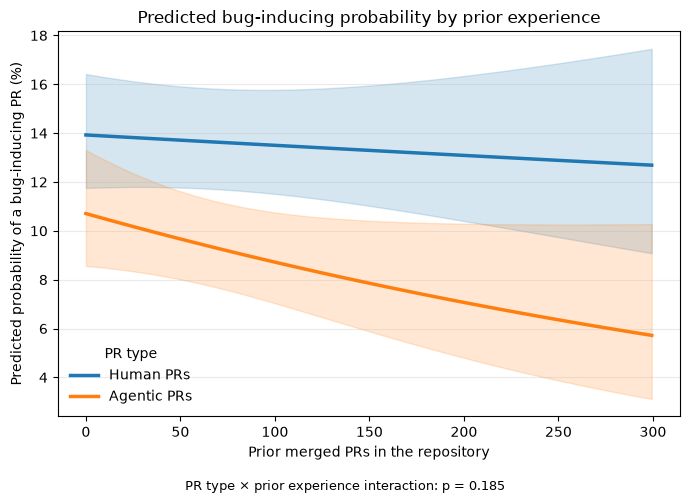

In [7]:
experience_grid = np.linspace(0, analysis["experience"].quantile(0.95))

fig, ax = plt.subplots(figsize=(7, 5))
for is_agentic, name in [(0, "Human PRs"), (1, "Agentic PRs")]:
    plot_data = pd.DataFrame({"is_agentic": is_agentic, "experience": experience_grid})
    pred = model.get_prediction(plot_data).summary_frame()

    (line,) = ax.plot(
        experience_grid,
        100 * pred["predicted"],
        linewidth=2.5,
        label=name,
    )
    ax.fill_between(
        experience_grid,
        100 * pred["ci_lower"],
        100 * pred["ci_upper"],
        color=line.get_color(),
        alpha=0.18,
    )

ax.set(
    title="Predicted bug-inducing probability by prior experience",
    xlabel="Prior merged PRs in the repository",
    ylabel="Predicted probability of a bug-inducing PR (%)",
)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="PR type", frameon=False)
fig.text(
    0.5,
    0.01,
    f"PR type × prior experience interaction: p = {model.pvalues[term]:.3f}",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()